<a href="https://colab.research.google.com/github/sofilukash/analysis_of_cyber_incidents_using_ml/blob/main/knn_intrusion_detection_logs_lab5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота 5
## Метод k найближчих сусідів (kNN) в системах машинного навчання

**Мета:** реалізувати метод k найближчих сусідів для виявлення мережевих вторгнень, визначити його переваги та недоліки та дослідити, як точність алгоритму залежить від особливостей датасету.

**Завдання:** реалізувати алгоритм k найближчих сусідів на одному з датасетів Kaggle (розділ *security*), визначити його переваги та недоліки, дослідити залежність точності алгоритму від особливостей використаного датасету.

**Датасет:** Network Intrusion Detection Logs ([Kaggle: developerghost/intrusion-detection-logs-normal-bot-scan](https://www.kaggle.com/datasets/developerghost/intrusion-detection-logs-normal-bot-scan)) — файл `Network_logs.csv`, 8 846 записів журналів мережевого трафіку (порт, протокол, тип запиту, user-agent, розмір корисного навантаження, статус). Бінарна класифікація: `Intrusion = 0` — нормальний трафік, `Intrusion = 1` — вторгнення (сканування портів або бот-атака). Другий файл архіву (`Time-Series_Network_logs.csv`, ті самі логи з міткою часу) у роботі не використовується.

**План роботи:**
1. Завантаження даних
2. Первинний аналіз даних
3. Підготовка даних
4. Реалізація алгоритму kNN
5. Базова модель
6. Залежність точності від особливостей датасету: масштабування, набір ознак, шумові ознаки, представлення порту, кількість сусідів `k`, метрика відстані, дисбаланс класів, артефакти датасету, розмір вибірки та час прогнозування
7. Підбір гіперпараметрів та підсумкова модель
8. Порівняння з іншими методами
9. Переваги та недоліки kNN
10. Загальні висновки

## 0. Імпорт бібліотек

In [1]:
import os, glob, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             ConfusionMatrixDisplay, classification_report)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

## 1. Завантаження даних
Файл береться з поточної папки; якщо його там немає — завантажується з Kaggle через `kagglehub`; якщо й це не вдалося — з'явиться вікно для ручного завантаження CSV.

In [2]:
FILE_NAME = "Network_logs.csv"

def find_dataset():
    if os.path.exists(FILE_NAME):
        return FILE_NAME
    try:
        try:
            import kagglehub
        except ImportError:
            import subprocess, sys
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
            import kagglehub
        folder = kagglehub.dataset_download("developerghost/intrusion-detection-logs-normal-bot-scan")
        csv_files = glob.glob(os.path.join(folder, "**", "*.csv"), recursive=True)
        csv_files.sort(key=lambda p: os.path.basename(p) != FILE_NAME)  # потрібний файл — першим
        if csv_files:
            return csv_files[0]
    except Exception as e:
        print("Автозавантаження з Kaggle не вдалося:", e)
    from google.colab import files
    print(f"Завантажте файл {FILE_NAME} вручну:")
    return next(iter(files.upload()))

raw = pd.read_csv(find_dataset())
print("Датасет завантажено:", raw.shape)

100%|██████████| 349k/349k [00:00<00:00, 35.0MB/s]

Extracting files...
Датасет завантажено: (8846, 10)


## 2. Первинний аналіз даних
Дивимось на структуру таблиці, пропуски, дублікати, баланс класів, а також на те, які ознаки пов'язані з міткою `Intrusion`.

In [3]:
print("Розмір таблиці:", raw.shape)
print("Пропусків (NaN):", int(raw.isna().sum().sum()), "| повних дублікатів:", int(raw.duplicated().sum()))
print("Унікальних значень:", raw.nunique().to_dict())

print("\nТип сканування Scan_Type проти мітки Intrusion:")
display(pd.crosstab(raw["Scan_Type"], raw["Intrusion"]))
raw.head()

Розмір таблиці: (8846, 10)
Пропусків (NaN): 0 | повних дублікатів: 0
Унікальних значень: {'Source_IP': 7565, 'Destination_IP': 8846, 'Port': 12, 'Request_Type': 7, 'Protocol': 3, 'Payload_Size': 3009, 'User_Agent': 6, 'Status': 2, 'Intrusion': 2, 'Scan_Type': 3}

Тип сканування Scan_Type проти мітки Intrusion:


Intrusion,0,1
Scan_Type,,
BotAttack,0,478
Normal,8000,0
PortScan,0,368


,Source_IP,Destination_IP,Port,Request_Type,Protocol,Payload_Size,User_Agent,Status,Intrusion,Scan_Type
0,192.168.142.55,42.156.67.167,80,FTP,UDP,2369,curl/7.68.0,Success,0,Normal
1,53.39.165.18,94.60.242.119,135,SMTP,UDP,1536,Wget/1.20.3,Failure,1,BotAttack
2,192.168.127.91,7.10.192.3,21,SMTP,TCP,1183,Wget/1.20.3,Success,0,Normal
3,192.168.30.40,130.169.82.211,25,HTTPS,TCP,666,Mozilla/5.0,Success,0,Normal
4,192.168.43.179,35.140.102.220,22,FTP,TCP,2821,Mozilla/5.0,Success,0,Normal


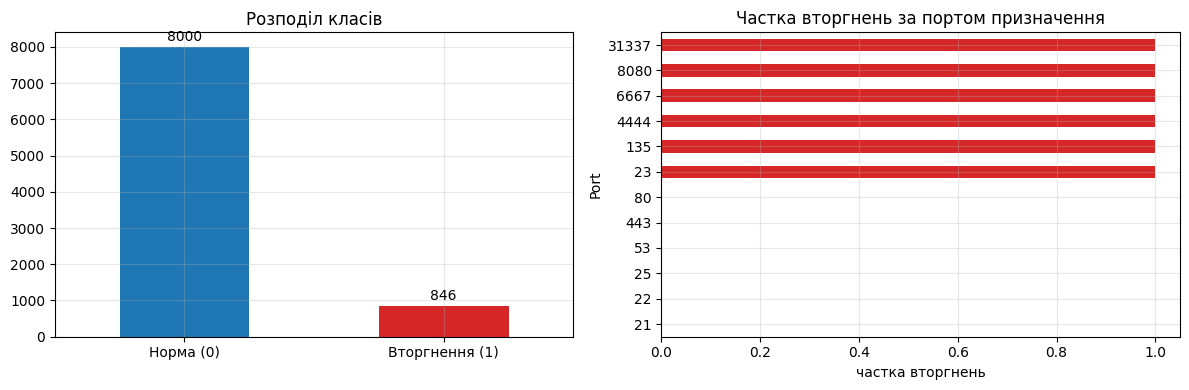

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

raw["Intrusion"].map({0: "Норма (0)", 1: "Вторгнення (1)"}).value_counts().plot.bar(ax=ax[0], rot=0, color=["tab:blue", "tab:red"])
ax[0].set_title("Розподіл класів"); ax[0].set_xlabel(""); ax[0].bar_label(ax[0].containers[0], padding=2)

rate_port = raw.groupby("Port")["Intrusion"].mean().sort_values()
rate_port.index = rate_port.index.astype(str)
rate_port.plot.barh(ax=ax[1], color=["tab:red" if v > 0.5 else "tab:blue" for v in rate_port])
ax[1].set_title("Частка вторгнень за портом призначення"); ax[1].set_xlabel("частка вторгнень"); ax[1].set_ylabel("Port")
plt.tight_layout(); plt.show()

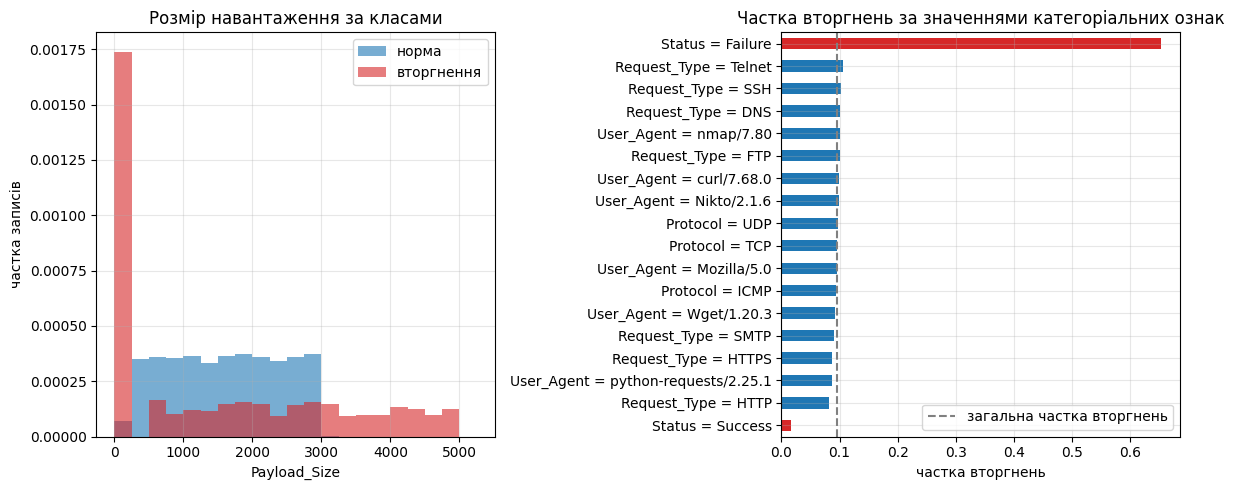

IP-адреса джерела проти мітки:


Intrusion,0,1
IP джерела внутрішня (192.168.*),,
False,0,846
True,8000,0


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

for lab, color, name in [(0, "tab:blue", "норма"), (1, "tab:red", "вторгнення")]:
    ax[0].hist(raw.loc[raw["Intrusion"] == lab, "Payload_Size"], bins=range(0, 5251, 250), alpha=0.6, color=color, label=name, density=True)
ax[0].set_xlabel("Payload_Size"); ax[0].set_ylabel("частка записів"); ax[0].set_title("Розмір навантаження за класами"); ax[0].legend()

rows = {f"{c} = {v}": raw.loc[raw[c] == v, "Intrusion"].mean()
        for c in ["Request_Type", "Protocol", "User_Agent", "Status"] for v in sorted(raw[c].unique())}
rates = pd.Series(rows).sort_values()
rates.plot.barh(ax=ax[1], color=["tab:red" if k.startswith("Status") else "tab:blue" for k in rates.index])
ax[1].axvline(raw["Intrusion"].mean(), color="gray", ls="--", label="загальна частка вторгнень")
ax[1].set_xlabel("частка вторгнень"); ax[1].set_title("Частка вторгнень за значеннями категоріальних ознак"); ax[1].legend()
plt.tight_layout(); plt.show()

internal = raw["Source_IP"].str.startswith("192.168.").rename("IP джерела внутрішня (192.168.*)")
print("IP-адреса джерела проти мітки:")
display(pd.crosstab(internal, raw["Intrusion"]))

**Висновок.** Датасет компактний (8 846 записів, 10 колонок), без пропусків і дублікатів; вторгнень 846 (≈ 9,6%), тож класи незбалансовані. Структура даних вказує на їх синтетичне походження: (1) колонка `Scan_Type` повністю збігається з міткою (Normal ↔ 0, PortScan/BotAttack ↔ 1) — це витік, її не можна використовувати як ознаку; (2) мітка однозначно визначається портом: на шести портах (23, 135, 4444, 6667, 8080, 31337) трафік завжди є вторгненням, на інших шести (21, 22, 25, 53, 80, 443) — завжди нормою; (3) усі нормальні записи мають внутрішню IP-адресу джерела (192.168.*), а всі вторгнення — зовнішню; (4) нормальне навантаження лежить у межах 200–3000 байт, а 66% вторгнень виходять за них (43% менше 200, 23% понад 3000); статус `Failure` мають 86% вторгнень проти 5% норми; (5) `Request_Type`, `Protocol` і `User_Agent` з міткою не пов'язані (частка вторгнень за їхніми значеннями 8–11%, як і в середньому). Датасет придатний для вивчення kNN, але високі показники слід інтерпретувати з урахуванням цих особливостей.

## 3. Підготовка даних
Етапи: визначаємо, які колонки не можна використовувати як ознаки → додаємо похідні колонки для експериментів → розділяємо на навчальну та тестову вибірки (80/20 зі збереженням пропорцій класів). Для kNN обов'язкові числове представлення ознак і узгоджений масштаб, тому категоріальні ознаки кодуємо `OneHotEncoder`, числові масштабуємо `StandardScaler`; все це вбудовано в `Pipeline`, тож параметри масштабування обчислюються лише на навчальних даних.

In [6]:
data = raw.copy()
data["src_internal"] = data["Source_IP"].str.startswith("192.168.").astype(int)   # лише для експерименту з артефактами (п. 6.8)
data["Port_cat"] = data["Port"].astype(str)                                       # порт як категорія (п. 6.4)

y = data["Intrusion"]
X = data.drop(columns=["Intrusion"])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

# Ознаки базової моделі. НЕ використовуємо: Scan_Type (прямо кодує мітку — витік),
# Destination_IP (унікальна для кожного рядка), Source_IP (ідентифікатор, а не властивість трафіку)
NUM = ["Port", "Payload_Size"]
CAT = ["Request_Type", "Protocol", "User_Agent", "Status"]
CV = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)

print(f"Навчальна вибірка: {len(X_train)}, тестова: {len(X_test)}")
print("Частка вторгнень: навчальна {:.3f}, тестова {:.3f}".format(y_train.mean(), y_test.mean()))
print(f"Базовий рівень (завжди прогнозувати «норма»): accuracy = {1 - y_test.mean():.4f}")

Навчальна вибірка: 7076, тестова: 1770
Частка вторгнень: навчальна 0.096, тестова 0.095
Базовий рівень (завжди прогнозувати «норма»): accuracy = 0.9045


In [7]:
def metrics(y_true, y_pred):
    return {"accuracy":  accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),   # частка справжніх вторгнень серед позначених як вторгнення
            "recall":    recall_score(y_true, y_pred),                       # частка виявлених вторгнень
            "f1":        f1_score(y_true, y_pred, zero_division=0)}

SCALERS = {"standard": StandardScaler, "minmax": MinMaxScaler, "none": None}

def make_preprocessor(num, cat, scaler="standard"):
    parts = []
    if num:
        parts.append(("num", SCALERS[scaler]() if SCALERS[scaler] else "passthrough", num))
    if cat:
        parts.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat))
    return ColumnTransformer(parts)

def make_pipeline(num, cat, scaler="standard", **knn_params):
    knn = KNeighborsClassifier(**{"n_neighbors": 5, **knn_params})
    return Pipeline([("prep", make_preprocessor(num, cat, scaler)), ("knn", knn)])

def evaluate_cv(pipe, data=None, resample=None):
    """5-кратна стратифікована крос-валідація на навчальній вибірці (тестова не використовується)."""
    data = X_train if data is None else data
    rows = []
    for tr, va in CV.split(data, y_train):
        Xa, ya = data.iloc[tr], y_train.iloc[tr]
        if resample:
            Xa, ya = resample(Xa, ya)            # перетворення лише навчальної частини фолда
        pred = clone(pipe).fit(Xa, ya).predict(data.iloc[va])
        rows.append(metrics(y_train.iloc[va], pred))
    res = pd.DataFrame(rows)
    return {**res.mean().to_dict(), "f1_std": res["f1"].std()}

def table(results):
    return pd.DataFrame(results).T[["accuracy", "precision", "recall", "f1", "f1_std"]]

**Висновок.** Базова модель використовує 6 вихідних ознак: дві числові (`Port`, `Payload_Size`) і чотири категоріальні; після one-hot кодування це 20 вимірів. `Scan_Type` виключено як витік мітки, `Destination_IP` — бо унікальна для кожного запису, `Source_IP` — як ідентифікатор. Розділення зберігає пропорцію класів (9,6% / 9,5% вторгнень). Тривіальний класифікатор «завжди норма» має accuracy 0,9045, тому accuracy сама по собі малоінформативна; основною метрикою обираємо F1 для вторгнень.

## 4. Реалізація алгоритму kNN
Алгоритм не має етапу навчання: він запам'ятовує всі навчальні приклади. Для нового об'єкта $x$ обчислюються відстані до всіх запам'ятованих об'єктів, обираються $k$ найближчих, і клас визначається голосуванням більшості. Відстані (з методички):

$$d_{\text{euclidean}}=\sqrt{\sum_i (x_i-y_i)^2},\qquad d_{\text{manhattan}}=\sum_i |x_i-y_i|,\qquad d_{\text{minkowski}}=\Bigl(\sum_i |x_i-y_i|^p\Bigr)^{1/p}.$$

Нижче — власна реалізація методом повного перебору (*brute force*, складність $O(N\cdot D)$ на один запит), яку перевіряємо порівнянням із `KNeighborsClassifier`.

In [8]:
class KNNManual:
    """k найближчих сусідів для бінарної мітки 0/1, повний перебір відстаней."""

    def __init__(self, k=5, metric="euclidean", p=3):
        self.k, self.metric, self.p = k, metric, p

    def fit(self, X, y):                                   # «навчання» — лише запам'ятовування вибірки
        self.X_, self.y_ = np.asarray(X, dtype=float), np.asarray(y)
        return self

    def predict(self, X, chunk=500):
        X = np.asarray(X, dtype=float)
        extra = {"p": self.p} if self.metric == "minkowski" else {}
        out = []
        for s in range(0, len(X), chunk):                  # порціями, щоб не зберігати величезну матрицю відстаней
            d = cdist(X[s:s + chunk], self.X_, metric=self.metric, **extra)
            nearest = np.argpartition(d, self.k - 1, axis=1)[:, :self.k]    # індекси k найближчих
            out.append((self.y_[nearest].mean(axis=1) > 0.5).astype(int))   # голосування більшості
        return np.concatenate(out)

Перевіряємо правильність реалізації на базових ознаках (`k = 5`, евклідова відстань).

In [9]:
prep = make_preprocessor(NUM, CAT).fit(X_train)
A_train, A_test = prep.transform(X_train), prep.transform(X_test)
print(f"Розмірність простору ознак після кодування: {A_train.shape[1]}")

pred_manual = KNNManual(k=5).fit(A_train, y_train).predict(A_test)
pred_sklearn = KNeighborsClassifier(n_neighbors=5).fit(A_train, y_train).predict(A_test)
print(f"Збіг прогнозів зі sklearn: {(pred_manual == pred_sklearn).mean():.2%}")
print("Метрики власної реалізації:", {k: round(v, 4) for k, v in metrics(y_test, pred_manual).items()})
print("Метрики sklearn:           ", {k: round(v, 4) for k, v in metrics(y_test, pred_sklearn).items()})

Розмірність простору ознак після кодування: 20
Збіг прогнозів зі sklearn: 100.00%
Метрики власної реалізації: {'accuracy': 0.974, 'precision': 0.9489, 'recall': 0.7692, 'f1': 0.8497}
Метрики sklearn:            {'accuracy': 0.974, 'precision': 0.9489, 'recall': 0.7692, 'f1': 0.8497}


**Висновок.** Власна реалізація повністю збігається з `KNeighborsClassifier`: прогнози збігаються у 100% випадків, метрики однакові. Добре видно головну особливість алгоритму: «навчання» — це лише збереження вибірки, а вся робота (обчислення відстаней до всіх 7 076 прикладів) відбувається під час прогнозування.

## 5. Базова модель
`KNeighborsClassifier` з параметрами за замовчуванням (`k = 5`, евклідова відстань, рівні ваги сусідів), усі ознаки «як є»: порт і розмір навантаження — числові (масштабовані), решта — one-hot.

,базова модель
accuracy,0.9740
precision,0.9489
recall,0.7692
f1,0.8497


              precision    recall  f1-score   support

       норма     0.9761    0.9956    0.9858      1601
  вторгнення     0.9489    0.7692    0.8497       169

    accuracy                         0.9740      1770
   macro avg     0.9625    0.8824    0.9177      1770
weighted avg     0.9735    0.9740    0.9728      1770



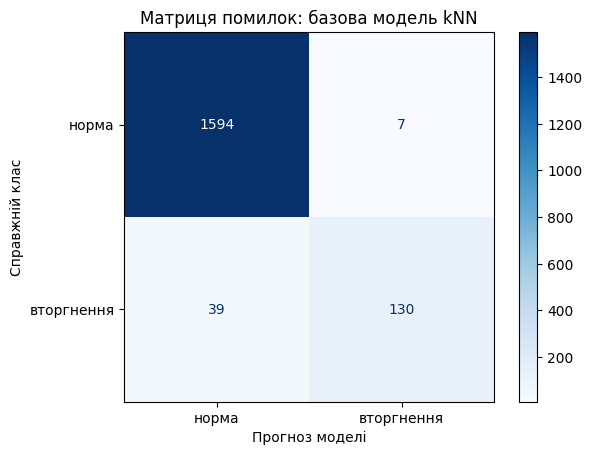

In [10]:
base = make_pipeline(NUM, CAT).fit(X_train, y_train)
base_pred = base.predict(X_test)
display(pd.Series(metrics(y_test, base_pred)).round(4).to_frame("базова модель"))
print(classification_report(y_test, base_pred, target_names=["норма", "вторгнення"], digits=4))

disp = ConfusionMatrixDisplay.from_predictions(y_test, base_pred, display_labels=["норма", "вторгнення"], cmap="Blues", values_format="d")
disp.ax_.grid(False); disp.ax_.set_title("Матриця помилок: базова модель kNN")
disp.ax_.set(xlabel="Прогноз моделі", ylabel="Справжній клас")
plt.show()

**Висновок.** Базова kNN має accuracy 0,974 (тривіальний класифікатор — 0,9045), але F1 для вторгнень лише 0,850: precision 0,949, recall 0,769, тобто модель пропускає майже чверть вторгнень (39 зі 169). Висока accuracy значною мірою пояснюється домінуванням нормального класу, тому далі орієнтуємось на F1.

## 6. Залежність точності від особливостей датасету
Змінюємо по одній особливості, решта — як у базовій моделі. Щоб не підганяти рішення під тестову вибірку, усі експерименти виконуються 5-кратною крос-валідацією на навчальній вибірці; в таблицях — середні значення метрик для класу «вторгнення» та стандартне відхилення F1 між фолдами (різниці менші за нього не варто вважати значущими). Основний критерій — F1, бо класи незбалансовані (≈ 90% / 10%), і accuracy завищує якість. Підсумкові значення F1 збираємо в `FACTORS`.

In [11]:
FACTORS = {}

def bar_f1(series, title, figsize=(8, 4)):
    ax = series.sort_values().plot.barh(figsize=figsize, color="tab:blue")
    ax.set_xlabel("F1 (вторгнення), крос-валідація"); ax.set_title(title); ax.set_xlim(0, 1.08)
    ax.bar_label(ax.containers[0], fmt="%.3f", padding=3); plt.tight_layout(); plt.show()

### 6.1. Масштабування ознак
kNN визначає схожість за відстанню, тому масштаб ознак безпосередньо впливає на результат. Порівнюємо відсутність масштабування, стандартизацію та нормалізацію до [0, 1].

In [12]:
res_scale = table({name: evaluate_cv(make_pipeline(NUM, CAT, scaler=s))
                   for name, s in [("без масштабування", "none"), ("StandardScaler", "standard"), ("MinMaxScaler", "minmax")]})
FACTORS["Масштабування"] = res_scale["f1"]
res_scale.round(4)

,accuracy,precision,recall,f1,f1_std
без масштабування,0.9887,1.0000,0.8818,0.9369,0.0184
StandardScaler,0.9758,0.9572,0.7827,0.8604,0.0361
MinMaxScaler,0.9474,0.7394,0.6955,0.7159,0.0378


**Висновок.** Масштабування суттєво змінює результат, але неочікувано: найкращий F1 — без масштабування (0,937), далі `StandardScaler` (0,860), найгірший — `MinMaxScaler` (0,716). Тобто масштабування не є універсальним покращенням: воно вирівнює вагу всіх ознак, зокрема й нерелевантних. Без масштабування відстань фактично визначається `Port` і `Payload_Size` (значення в тисячах), які якраз інформативні, а one-hot-ознаки майже не впливають; результат (0,937) близький до моделі лише на `Port + Payload_Size` зі стандартизацією (0,934, п. 6.2). Після стандартизації нерелевантні категоріальні ознаки отримують вагу, співмірну з портом, і «розмивають» відстань; `MinMaxScaler` стискає різницю між портами (крім 31337) до часток одиниці, тож їх переважують one-hot-ознаки.

### 6.2. Набір ознак
Класифікуємо, використовуючи різні підмножини ознак, щоб побачити, які з них несуть інформацію про мітку, а які лише «додають шум» у відстань.

,accuracy,precision,recall,f1,f1_std
лише Port,1.0000,1.0000,1.0000,1.0000,0.0000
лише Payload_Size,0.9666,0.9957,0.6543,0.7891,0.0291
лише Status,0.9450,0.6639,0.8626,0.7502,0.0132
лише Request_Type + Protocol + User_Agent,0.8964,0.0908,0.0118,0.0206,0.0144
Port + Payload_Size,0.9883,1.0000,0.8774,0.9345,0.0170
Port + Status,1.0000,1.0000,1.0000,1.0000,0.0000
Port + Payload_Size + Status,0.9876,0.9821,0.8862,0.9314,0.0184
усі ознаки (базова модель),0.9758,0.9572,0.7827,0.8604,0.0361


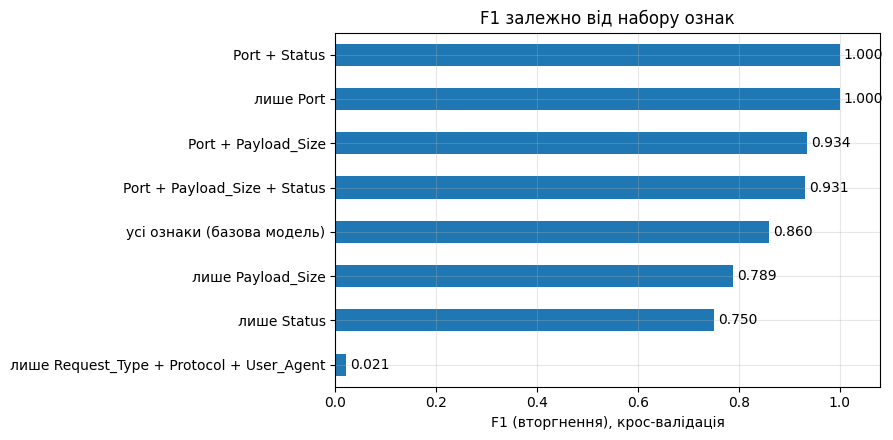

In [13]:
subsets = {
    "лише Port":                                   (["Port"], []),
    "лише Payload_Size":                           (["Payload_Size"], []),
    "лише Status":                                 ([], ["Status"]),
    "лише Request_Type + Protocol + User_Agent":   ([], ["Request_Type", "Protocol", "User_Agent"]),
    "Port + Payload_Size":                         (NUM, []),
    "Port + Status":                               (["Port"], ["Status"]),
    "Port + Payload_Size + Status":                (NUM, ["Status"]),
    "усі ознаки (базова модель)":                  (NUM, CAT),
}
res_subsets = table({name: evaluate_cv(make_pipeline(n, c)) for name, (n, c) in subsets.items()})
FACTORS["Набір ознак"] = res_subsets["f1"]
display(res_subsets.round(4))
bar_f1(res_subsets["f1"], "F1 залежно від набору ознак", figsize=(9, 4.5))

**Висновок.** Якість визначається тим, які ознаки є в наборі, а не їхньою кількістю. Лише `Port` або `Port + Status` дають F1 = 1,0, а додавання інших ознак його знижує: `Port + Payload_Size` — 0,934, усі ознаки — 0,860. Три ознаки (`Request_Type`, `Protocol`, `User_Agent`) самі по собі не пов'язані з міткою (F1 = 0,02), тож у повному наборі вони лише додають шум у відстань. Це головна слабкість kNN: він не вміє сам обирати важливі ознаки, усі вони рівноправно впливають на відстань, тому набір ознак потрібно підбирати вручну.

### 6.3. Шумові (нерелевантні) ознаки
До найкращої ознаки (`Port`) додаємо `N` ознак із випадковим шумом, не пов'язаних із міткою. Так імітується датасет із великою кількістю неінформативних колонок.

,accuracy,precision,recall,f1,f1_std
кількість шумових ознак,,,,,
0,1.0000,1.0000,1.0000,1.0000,0.0000
1,0.9685,0.9956,0.6734,0.8025,0.0371
2,0.9683,0.9978,0.6705,0.8010,0.0388
5,0.9593,0.9953,0.5774,0.7302,0.0279
10,0.9398,0.9885,0.3752,0.5436,0.0231
20,0.9217,0.9480,0.1920,0.3192,0.0275
50,0.9178,0.8824,0.1625,0.2741,0.0190


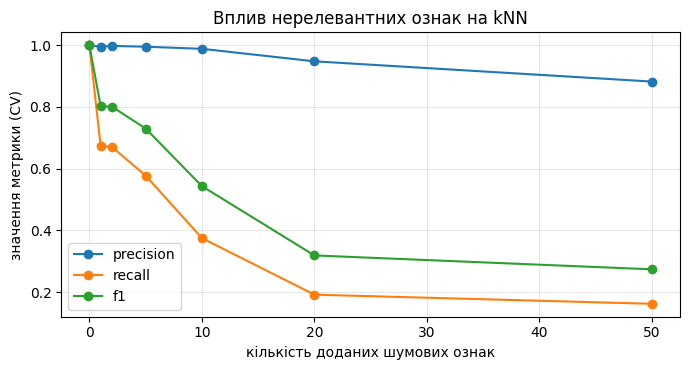

In [14]:
rng = np.random.default_rng(RANDOM_STATE)
noise = pd.DataFrame(rng.normal(size=(len(X_train), 50)), index=X_train.index,
                     columns=[f"noise{i}" for i in range(50)])
X_noisy = pd.concat([X_train, noise], axis=1)

res_noise = table({n: evaluate_cv(make_pipeline(["Port"] + list(noise.columns[:n]), []), data=X_noisy)
                   for n in [0, 1, 2, 5, 10, 20, 50]})
res_noise.index.name = "кількість шумових ознак"
FACTORS["Шумові ознаки"] = res_noise["f1"]
display(res_noise.round(4))

ax = res_noise[["precision", "recall", "f1"]].plot(marker="o", figsize=(7, 3.8))
ax.set_xlabel("кількість доданих шумових ознак"); ax.set_ylabel("значення метрики (CV)")
ax.set_title("Вплив нерелевантних ознак на kNN"); plt.tight_layout(); plt.show()

**Висновок.** kNN дуже чутливий до нерелевантних ознак: коли до `Port` (F1 = 1,0) додано лише одну шумову ознаку, F1 падає до 0,80 (recall 0,67), а при 50 шумових ознаках — до 0,27 (recall 0,16). Різниці між портами, які на шкалі стандартизованих значень становлять соті частки одиниці (зокрема 23 і 135 порівняно з нормальними 21–443), на тлі шуму з одиничною дисперсією перестають впливати на відстань, і сусіди обираються майже випадково. Precision при цьому залишається високою (≥ 0,88): модель стає «обережною» і пропускає вторгнення. Це ілюстрація «прокляття розмірності»: зі зростанням кількості ознак відстані між точками вирівнюються.

### 6.4. Представлення ознаки Port
`Port` — це ідентифікатор сервісу, а не величина: порти 22 і 23 числово «близькі», але нічого спільного між собою не мають. Порівнюємо числове та категоріальне (one-hot) представлення порту.

In [15]:
res_port = table({
    "Port — числовий (як у базовій)":  evaluate_cv(make_pipeline(NUM, CAT)),
    "Port — категоріальний (one-hot)": evaluate_cv(make_pipeline(["Payload_Size"], CAT + ["Port_cat"])),
})
FACTORS["Представлення порту"] = res_port["f1"]
res_port.round(4)

,accuracy,precision,recall,f1,f1_std
Port — числовий (як у базовій),0.9758,0.9572,0.7827,0.8604,0.0361
Port — категоріальний (one-hot),0.9812,0.9674,0.8316,0.8943,0.0210


**Висновок.** Категоріальне представлення порту дає трохи кращий результат (F1 0,894 проти 0,860; recall 0,832 проти 0,783), але різниця менша за розкид між фолдами (≈ 0,02–0,04), тому статистично переконливою вона не є. Теоретично порт правильніше кодувати як категорію, бо числова відстань між номерами портів не відображає схожості сервісів, проте в цьому датасеті виграш невеликий.

### 6.5. Кількість сусідів k
Мале `k` — модель надто чутлива до окремих точок (перенавчання), велике — надто «згладжена» (недонавчання); при незбалансованих класах великі `k` ще й заглушують менший клас.

,accuracy,precision,recall,f1,f1_std
k,,,,,
1,0.9640,0.8268,0.7871,0.8058,0.0421
3,0.9712,0.9087,0.7769,0.8373,0.0182
5,0.9758,0.9572,0.7827,0.8604,0.0361
7,0.9771,0.9868,0.7709,0.8650,0.0298
11,0.9756,0.9884,0.7532,0.8542,0.0331
15,0.9719,0.9935,0.7104,0.8279,0.0327
21,0.9650,0.9885,0.6409,0.7765,0.0426
31,0.9624,1.0000,0.6069,0.7547,0.0339
51,0.9655,1.0000,0.6394,0.7787,0.0446


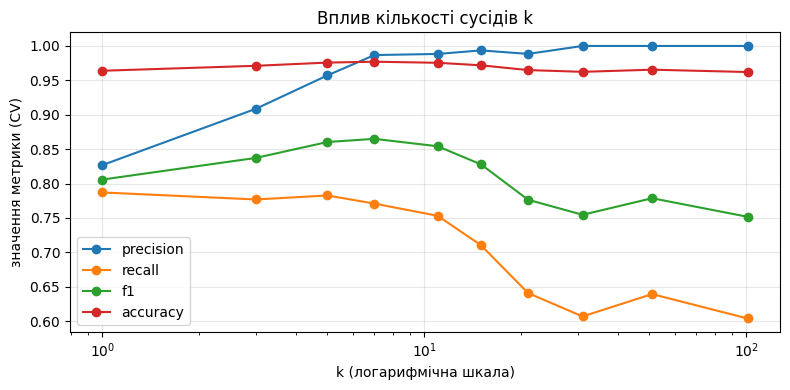

In [16]:
ks = [1, 3, 5, 7, 11, 15, 21, 31, 51, 101]
res_k = table({k: evaluate_cv(make_pipeline(NUM, CAT, n_neighbors=k)) for k in ks})
res_k.index.name = "k"
FACTORS["Кількість сусідів k"] = res_k["f1"]
display(res_k.round(4))

ax = res_k[["precision", "recall", "f1", "accuracy"]].plot(marker="o", figsize=(8, 4), logx=True)
ax.set_xlabel("k (логарифмічна шкала)"); ax.set_ylabel("значення метрики (CV)"); ax.set_title("Вплив кількості сусідів k")
plt.tight_layout(); plt.show()

**Висновок.** Залежність від `k` має характерну форму: при `k = 1` модель найчутливіша до окремих точок (precision 0,83 — багато хибних тривог, F1 0,806), оптимум припадає на `k` ≈ 5–11 (F1 0,854–0,865), а при великих `k` (≥ 21) recall різко падає (до ≈ 0,60 при `k = 101`) за precision 1,0: оскільки вторгнень лише ≈ 10%, серед багатьох сусідів переважає нормальний клас, і менший клас «заглушається». Отже, оптимальне `k` залежить від розміру та балансу класів; значення в діапазоні 5–11 за F1 статистично не відрізняються.

### 6.6. Метрика відстані та ваги сусідів
Порівнюємо метрики з методички (евклідова, манхеттенська, Мінковського з `p = 3`), а також метрику Чебишова та зважене голосування (`weights='distance'` — ближчі сусіди мають більшу вагу). `k = 5`.

In [17]:
res_metric = table({
    "euclidean":                    evaluate_cv(make_pipeline(NUM, CAT)),
    "manhattan":                    evaluate_cv(make_pipeline(NUM, CAT, metric="manhattan")),
    "minkowski, p=3":               evaluate_cv(make_pipeline(NUM, CAT, metric="minkowski", p=3)),
    "chebyshev":                    evaluate_cv(make_pipeline(NUM, CAT, metric="chebyshev")),
    "euclidean + weights=distance": evaluate_cv(make_pipeline(NUM, CAT, weights="distance")),
})
FACTORS["Метрика відстані"] = res_metric["f1"]
res_metric.round(4)

,accuracy,precision,recall,f1,f1_std
euclidean,0.9758,0.9572,0.7827,0.8604,0.0361
manhattan,0.9705,0.9353,0.7428,0.8272,0.0331
"minkowski, p=3",0.9795,0.9621,0.8182,0.8836,0.0363
chebyshev,0.9693,0.9869,0.6882,0.8098,0.0453
euclidean + weights=distance,0.9716,0.9146,0.7753,0.8382,0.0386


**Висновок.** Метрика впливає помірно: найкращий F1 — у метрики Мінковського з `p = 3` (0,884) та евклідової (0,860), нижчий — у манхеттенської (0,827) і Чебишова (0,810, recall лише 0,688). Проте різниці між метриками в межах 1–2 стандартних відхилень F1 між фолдами (≈ 0,03–0,05), тож це лише тенденція; імовірно, більші `p` сильніше враховують ознаки з найбільшою різницею (порт і навантаження). Зважування за відстанню (`weights='distance'`) покращення не дало (0,838 проти 0,860).

### 6.7. Дисбаланс класів
Вторгнень у даних ≈ 10%. Зменшуємо кількість нормальних записів у навчальній частині кожного фолда (випадкове видалення) до співвідношення норма : вторгнення = 3 : 1 та 1 : 1; оцінка проводиться на незміненій валідаційній частині.

In [18]:
def undersample(ratio):
    def f(Xa, ya):
        neg = ya[ya == 0].sample(n=min((ya == 0).sum(), ratio * (ya == 1).sum()), random_state=RANDOM_STATE).index
        keep = ya[ya == 1].index.union(neg)
        return Xa.loc[keep], ya.loc[keep]
    return f

res_bal = table({
    "початкове співвідношення (≈ 9 : 1)": evaluate_cv(make_pipeline(NUM, CAT)),
    "норма : вторгнення = 3 : 1":         evaluate_cv(make_pipeline(NUM, CAT), resample=undersample(3)),
    "норма : вторгнення = 1 : 1":         evaluate_cv(make_pipeline(NUM, CAT), resample=undersample(1)),
})
FACTORS["Дисбаланс класів"] = res_bal["f1"]
res_bal.round(4)

,accuracy,precision,recall,f1,f1_std
початкове співвідношення (≈ 9 : 1),0.9758,0.9572,0.7827,0.8604,0.0361
норма : вторгнення = 3 : 1,0.9682,0.8485,0.8138,0.8304,0.0250
норма : вторгнення = 1 : 1,0.9490,0.6798,0.8848,0.7685,0.0077


**Висновок.** Видалення частини нормальних записів з навчальних даних зсуває баланс між precision і recall: при співвідношенні 1 : 1 recall зростає з 0,783 до 0,885, але precision падає з 0,957 до 0,680 (багато хибних тривог), тому F1 знижується до 0,769. Для kNN це закономірно: прогноз визначається сусідами, і чим менше нормальних точок, тим частіше поруч з нормальним об'єктом опиняються точки вторгнень. Вибір балансу — це вибір між пропущеними вторгненнями та хибними тривогами залежно від вартості кожної помилки.

### 6.8. Артефакти датасету
Додаємо до базових ознак дві колонки, які в реальній системі були б недоступні або недоречні: `Scan_Type` (тип атаки, з якого прямо випливає мітка) та `src_internal` (чи є IP-адреса джерела внутрішньою, `192.168.*`).

In [19]:
res_art = table({
    "базова модель":                                   evaluate_cv(make_pipeline(NUM, CAT)),
    "+ src_internal (внутрішня IP джерела)":           evaluate_cv(make_pipeline(NUM + ["src_internal"], CAT)),
    "+ Scan_Type (прямий витік мітки)":                evaluate_cv(make_pipeline(NUM, CAT + ["Scan_Type"])),
})
FACTORS["Артефакти датасету"] = res_art["f1"]
res_art.round(4)

,accuracy,precision,recall,f1,f1_std
базова модель,0.9758,0.9572,0.7827,0.8604,0.0361
+ src_internal (внутрішня IP джерела),1.0000,1.0000,1.0000,1.0000,0.0000
+ Scan_Type (прямий витік мітки),0.9945,1.0000,0.9424,0.9702,0.0106


**Висновок.** Артефакти датасету дають «ідеальні» результати: ознака `src_internal` (внутрішня/зовнішня IP-адреса) піднімає F1 до 1,0, а `Scan_Type` — до 0,970. Така точність зумовлена тим, як згенеровано дані (нормальний трафік — із внутрішніх адрес, атаки — із зовнішніх; тип сканування — по суті сама мітка), а не якістю моделі, і в реальній системі вона б не відтворилася. Цікаво, що навіть прямий витік мітки (`Scan_Type`) не дає kNN 100%: інші ознаки продовжують впливати на відстань і розбавляють найінформативнішу, — ще одна ілюстрація нездатності kNN самостійно виділяти важливі ознаки.

### 6.9. Розмір вибірки та час прогнозування
kNN не «навчається», але кожен прогноз вимагає пошуку сусідів серед усіх запам'ятованих прикладів. Дивимось, як від розміру навчальної вибірки залежать точність і час прогнозування, і порівнюємо алгоритми пошуку сусідів з методички: `brute` (повний перебір), `kd_tree` та `ball_tree`.

In [20]:
full = int(len(X_train) * 0.8)                       # розмір навчальної частини одного фолда
def take(n):
    def f(Xa, ya):
        if n >= len(Xa) - 1:                              # «усі дані» (розміри фолдів відрізняються на 1 рядок)
            return Xa, ya
        Xs, _, ys, _ = train_test_split(Xa, ya, train_size=n, stratify=ya, random_state=RANDOM_STATE)
        return Xs, ys
    return f

res_size = table({n: evaluate_cv(make_pipeline(NUM, CAT), resample=take(n)) for n in [100, 200, 500, 1000, 2000, 4000, full]})
res_size.index.name = "розмір навчальної вибірки"
FACTORS["Розмір вибірки"] = res_size["f1"]
display(res_size.round(4))

,accuracy,precision,recall,f1,f1_std
розмір навчальної вибірки,,,,,
100,0.9450,0.9967,0.4267,0.5939,0.0782
200,0.9556,0.9923,0.5404,0.6969,0.0650
500,0.9628,0.9828,0.6232,0.7607,0.0457
1000,0.9644,0.9821,0.6394,0.7733,0.0428
2000,0.9700,0.9816,0.7000,0.8167,0.0257
4000,0.9754,0.9757,0.7621,0.8552,0.0293
5660,0.9758,0.9572,0.7827,0.8604,0.0361


Розмірність простору ознак: 20; запитів: 1770


,"brute, мс","kd_tree, мс","ball_tree, мс"
розмір навчальної вибірки,,,
500,6.6,31.0,34.3
1000,10.4,53.7,60.8
2000,19.6,82.0,113.6
4000,35.7,109.9,199.3
7076,63.2,137.1,388.4


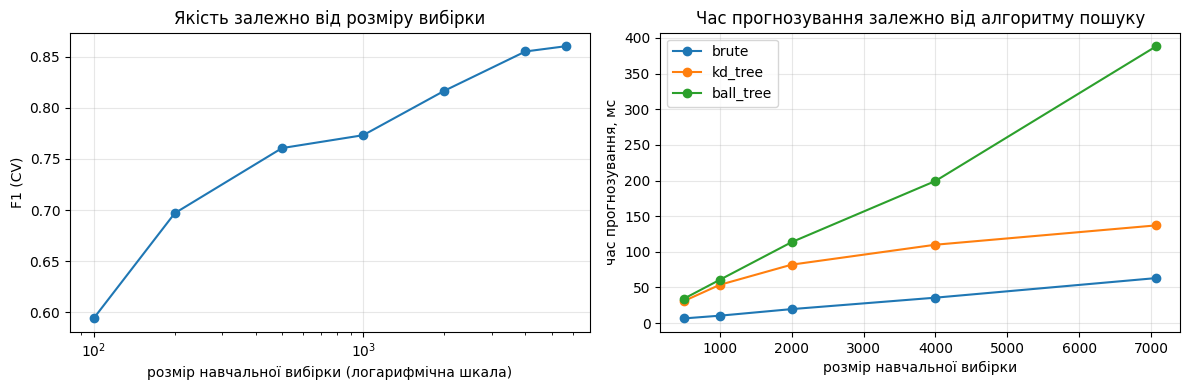

In [21]:
# час прогнозування для 1 770 тестових запитів
rng = np.random.default_rng(RANDOM_STATE)
sizes = [500, 1000, 2000, 4000, len(A_train)]
times = {}
for alg in ["brute", "kd_tree", "ball_tree"]:
    row = {}
    for n in sizes:
        idx = rng.choice(len(A_train), n, replace=False) if n < len(A_train) else np.arange(len(A_train))
        knn = KNeighborsClassifier(n_neighbors=5, algorithm=alg).fit(A_train[idx], y_train.iloc[idx])
        best = min((lambda t0: (knn.predict(A_test), time.perf_counter() - t0)[1])(time.perf_counter()) for _ in range(3))
        row[n] = best * 1000
    times[alg] = row
res_time = pd.DataFrame(times); res_time.index.name = "розмір навчальної вибірки"
print(f"Розмірність простору ознак: {A_train.shape[1]}; запитів: {len(A_test)}")
display(res_time.round(1).rename(columns=lambda c: c + ", мс"))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
res_size["f1"].plot(marker="o", logx=True, ax=ax[0], color="tab:blue")
ax[0].set_xlabel("розмір навчальної вибірки (логарифмічна шкала)"); ax[0].set_ylabel("F1 (CV)"); ax[0].set_title("Якість залежно від розміру вибірки")
res_time.plot(marker="o", ax=ax[1]); ax[1].set_xlabel("розмір навчальної вибірки"); ax[1].set_ylabel("час прогнозування, мс")
ax[1].set_title("Час прогнозування залежно від алгоритму пошуку")
plt.tight_layout(); plt.show()

**Висновок.** Чим більше навчальних даних, тим точніший kNN: F1 зростає з 0,59 (100 прикладів) до 0,86 (≈ 5 660), причому на малих вибірках страждає насамперед recall (0,43 при 100 прикладах), бо вторгнень у вибірці мало. Водночас час прогнозування зростає разом з вибіркою: для `brute` приблизно у 8 разів (з ≈ 3 до ≈ 20–25 мс на 1 770 запитів) при збільшенні вибірки з 500 до 7 076 прикладів (абсолютні значення часу залежать від комп'ютера). Дерева (`kd_tree`, `ball_tree`) у цьому випадку повільніші за повний перебір: простір має 20 вимірів (здебільшого one-hot), а за методичкою KD-дерево ефективне лише при D < 20 і деградує в просторах більшої розмірності («прокляття розмірності»). Водночас час `kd_tree` при тому ж зростанні вибірки збільшується лише приблизно у 4 рази (проти ≈ 8 разів у `brute`), тож на набагато більших вибірках дерево, можливо, виграло б, але в цьому експерименті цього не видно.

### 6.10. Зведення: який фактор впливає найсильніше
Для кожного фактора — мінімальне та максимальне значення F1 серед перевірених варіантів; «розмах» показує чутливість якості до цього фактора.

,min F1,max F1,розмах
Представлення порту,0.8604,0.8943,0.0338
Метрика відстані,0.8098,0.8836,0.0738
Дисбаланс класів,0.7685,0.8604,0.0919
Кількість сусідів k,0.7517,0.8650,0.1133
Артефакти датасету,0.8604,1.0000,0.1396
Масштабування,0.7159,0.9369,0.2210
Розмір вибірки,0.5939,0.8604,0.2665
Шумові ознаки,0.2741,1.0000,0.7259
Набір ознак,0.0206,1.0000,0.9794


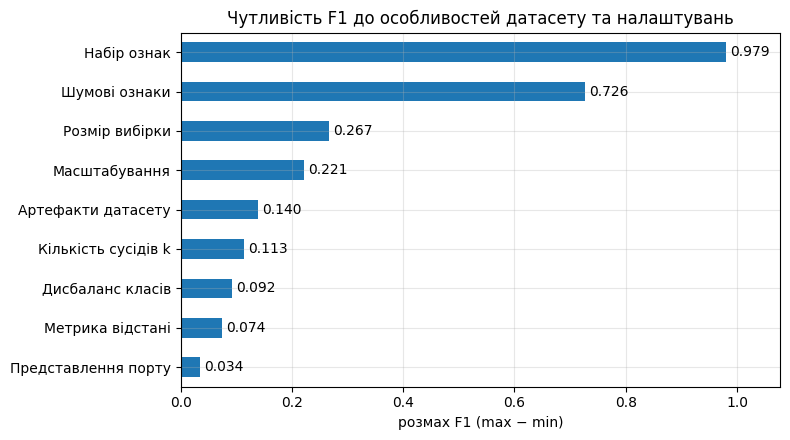

In [22]:
summary_df = pd.DataFrame({k: {"min F1": v.min(), "max F1": v.max(), "розмах": v.max() - v.min()}
                           for k, v in FACTORS.items()}).T.sort_values("розмах")
display(summary_df.round(4))

ax = summary_df["розмах"].plot.barh(figsize=(8, 4.5), color="tab:blue")
ax.set_xlabel("розмах F1 (max − min)"); ax.set_title("Чутливість F1 до особливостей датасету та налаштувань")
ax.bar_label(ax.containers[0], fmt="%.3f", padding=3); ax.margins(x=0.1); plt.tight_layout(); plt.show()

**Висновок.** За розмахом F1 найсильніше на kNN впливають набір ознак (0,98) і наявність шумових ознак (0,73), далі — розмір навчальної вибірки (0,27) і масштабування (0,22); налаштування самого алгоритму (кількість сусідів, метрика, баланс класів) змінюють F1 на 0,07–0,11, а представлення порту — лише на 0,03 (у межах розкиду). Отже, якість kNN визначається насамперед даними (які ознаки є і в якому масштабі), а не підбором параметрів. Порівняння орієнтовне, бо розмах залежить від діапазону перевірених значень; для артефактів F1 до 1,0 — наслідок витоку, а не якості моделі.

## 7. Підбір гіперпараметрів та підсумкова модель
З урахуванням експериментів підсумкова модель використовує лише ознаки, пов'язані з міткою (`Port` як категорія, `Status`, `Payload_Size`), без шумових і без артефактів (`Scan_Type`, IP-адреси). Параметри `k`, ваги сусідів і метрику (`p = 1` — манхеттенська, `p = 2` — евклідова) підбираємо `GridSearchCV` за F1 на навчальній вибірці. Тестова вибірка використовується лише для фінальної оцінки.

,n_neighbors,weights,p,mean_test_score,std_test_score
0,1,uniform,1,1.0,0.0
1,1,distance,1,1.0,0.0
2,1,uniform,2,1.0,0.0
3,1,distance,2,1.0,0.0
4,3,uniform,1,1.0,0.0
5,3,distance,1,1.0,0.0
6,3,distance,2,1.0,0.0
7,5,distance,1,1.0,0.0


Найкращі параметри: {'knn__n_neighbors': 1, 'knn__p': 1, 'knn__weights': 'uniform'} | CV F1 = 1.0


,підсумкова модель (тест)
accuracy,1.0
precision,1.0
recall,1.0
f1,1.0


              precision    recall  f1-score   support

       норма     1.0000    1.0000    1.0000      1601
  вторгнення     1.0000    1.0000    1.0000       169

    accuracy                         1.0000      1770
   macro avg     1.0000    1.0000    1.0000      1770
weighted avg     1.0000    1.0000    1.0000      1770



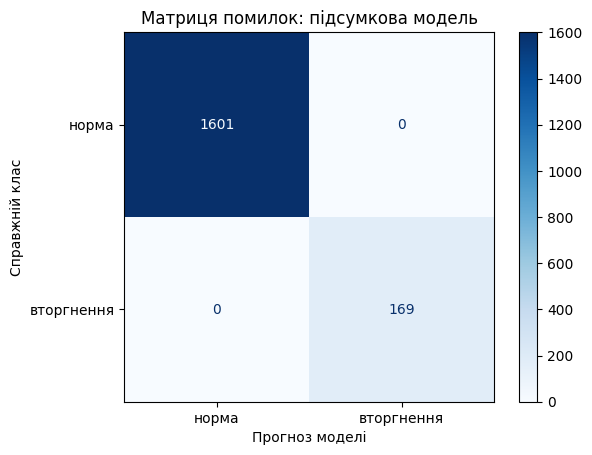

In [23]:
final_pipe = make_pipeline(["Payload_Size"], ["Port_cat", "Status"])
param_grid = {"knn__n_neighbors": [1, 3, 5, 7, 11, 15, 21],
              "knn__weights": ["uniform", "distance"],
              "knn__p": [1, 2]}
grid = GridSearchCV(final_pipe, param_grid, scoring="f1", cv=CV, n_jobs=-1)
grid.fit(X_train, y_train)

top = (pd.DataFrame(grid.cv_results_)[["param_knn__n_neighbors", "param_knn__weights", "param_knn__p", "mean_test_score", "std_test_score"]]
       .rename(columns=lambda c: c.replace("param_knn__", "")).sort_values("mean_test_score", ascending=False))
display(top.head(8).round(4).reset_index(drop=True))
print("Найкращі параметри:", grid.best_params_, "| CV F1 =", round(grid.best_score_, 4))

best = grid.best_estimator_
final_pred = best.predict(X_test)
display(pd.Series(metrics(y_test, final_pred)).round(4).to_frame("підсумкова модель (тест)"))
print(classification_report(y_test, final_pred, target_names=["норма", "вторгнення"], digits=4))

disp = ConfusionMatrixDisplay.from_predictions(y_test, final_pred, display_labels=["норма", "вторгнення"], cmap="Blues", values_format="d")
disp.ax_.grid(False); disp.ax_.set_title("Матриця помилок: підсумкова модель")
disp.ax_.set(xlabel="Прогноз моделі", ylabel="Справжній клас")
plt.show()

**Висновок.** Підсумкова модель на тесті дає accuracy = precision = recall = F1 = 1,0, тобто жодної помилки на 1 770 записах (серед них 169 вторгнень, з яких базова модель пропускала 39). Це суттєво вище за базову kNN (F1 0,850), але це результат підбору ознак на синтетичному датасеті, де клас однозначно визначається портом; він не свідчить про «ідеальність» kNN і не гарантує такої якості на реальному трафіку.

## 8. Порівняння з іншими методами
Порівнюємо kNN з методами з попередніх робіт та випадковим лісом на тестовій вибірці. Усі «інші» методи отримують ті самі ознаки «як є», що й базова kNN (порт — числовий), щоб побачити, наскільки метод чутливий до представлення даних. Також вимірюємо час навчання та прогнозування.

,accuracy,precision,recall,f1,"навчання, мс","прогноз, мс"
"kNN, базова (k=5)",0.9740,0.9489,0.7692,0.8497,15.7424,66.2718
"kNN, підсумкова",1.0000,1.0000,1.0000,1.0000,21.2220,57.2846
Логістична регресія,0.9650,0.9147,0.6982,0.7919,29.7395,6.9570
SVM (RBF),0.9836,0.9605,0.8639,0.9097,207.4060,45.1008
Random Forest,0.9938,0.9877,0.9467,0.9668,790.2593,59.9166


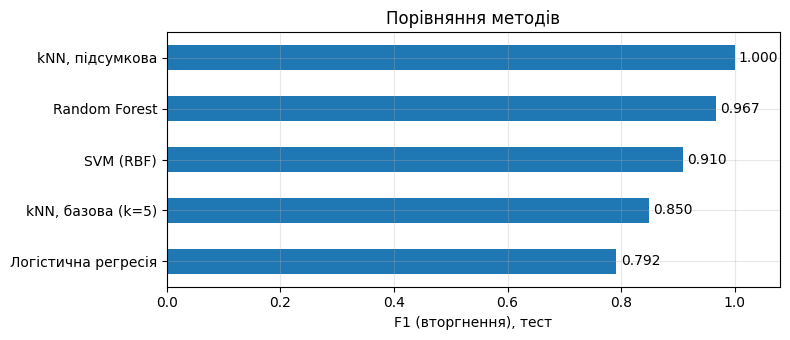

In [24]:
models = {
    "kNN, базова (k=5)":             make_pipeline(NUM, CAT),
    "kNN, підсумкова":               best,
    "Логістична регресія":           Pipeline([("prep", make_preprocessor(NUM, CAT)), ("m", LogisticRegression(max_iter=2000))]),
    "SVM (RBF)":                     Pipeline([("prep", make_preprocessor(NUM, CAT)), ("m", SVC())]),
    "Random Forest":                 Pipeline([("prep", make_preprocessor(NUM, CAT)), ("m", RandomForestClassifier(200, random_state=RANDOM_STATE, n_jobs=-1))]),
}
rows = {}
for name, model in models.items():
    m = clone(model)
    t0 = time.perf_counter(); m.fit(X_train, y_train); fit_t = time.perf_counter() - t0
    t0 = time.perf_counter(); pred = m.predict(X_test); pred_t = time.perf_counter() - t0
    rows[name] = {**metrics(y_test, pred), "навчання, мс": fit_t * 1000, "прогноз, мс": pred_t * 1000}
comparison = pd.DataFrame(rows).T
display(comparison.round(4))

ax = comparison["f1"].sort_values().plot.barh(figsize=(8, 3.5), color="tab:blue")
ax.set_xlabel("F1 (вторгнення), тест"); ax.set_title("Порівняння методів"); ax.set_xlim(0, 1.08)
ax.bar_label(ax.containers[0], fmt="%.3f", padding=3); plt.tight_layout(); plt.show()

**Висновок.** На однакових «сирих» ознаках найкращий Random Forest (F1 ≈ 0,967), далі SVM (≈ 0,910), kNN (0,850) і логістична регресія (≈ 0,792): дерева самі відбирають інформативні ознаки (порт) і нечутливі до масштабу та шуму, тоді як kNN і SVM залежать від відстаней. Підсумкова kNN із підібраними ознаками (1,0) випереджає всі моделі, але порівняння не зовсім рівне: їй надано відібрані ознаки, іншим — ні. Це показує, що для kNN підготовка ознак важливіша за вибір самого алгоритму. За часом kNN «навчається» майже миттєво (час у таблиці — це переважно підготовка даних), а прогноз у нашому запуску повільніший, ніж у логістичної регресії; на цьому малому наборі різниця невелика, але зростає з розміром вибірки (п. 6.9).

## 9. Переваги та недоліки kNN
**Переваги** (з підтвердженням у роботі):
- **Простота.** Немає етапу навчання й складних припущень; реалізація — кілька рядків коду (п. 4), з єдиним суттєвим параметром `k`.
- **Непараметричність.** Алгоритм не припускає певної форми межі між класами; на чистому наборі ознак він досяг F1 = 1,0 (п. 7).
- **Інтерпретованість.** Рішення можна пояснити конкретними схожими записами, які стали «сусідами».
- **Легко оновлювати.** Нові приклади додаються до вибірки без перенавчання моделі.
- **Висока якість за правильних ознак.** За підібраного набору ознак (`Port` + `Status`) — F1 = 1,0, на `Port + Payload_Size` — 0,93 (п. 6.2).

**Недоліки** (з підтвердженням у роботі):
- **Чутливість до нерелевантних ознак.** Одна шумова ознака знижує F1 з 1,0 до 0,80, 50 — до 0,27 (п. 6.3); алгоритм сам не вибирає важливі ознаки (п. 6.2).
- **Залежність від масштабу та представлення ознак.** Залежно від масштабування F1 змінюється від 0,72 до 0,94 (п. 6.1).
- **Чутливість до `k` та дисбалансу класів.** При `k` ≥ 21 recall меншого класу падає до ≈ 0,60 (п. 6.5); вирівнювання класів змінює співвідношення precision/recall (п. 6.7).
- **Повільне прогнозування й витрати пам'яті.** Зберігається вся вибірка, час прогнозування росте з її розміром (п. 6.9); у просторі з ≈ 20 вимірами дерева пошуку не прискорюють роботу.
- **Погано працює на малих вибірках рідкісного класу.** При 100 навчальних прикладах F1 лише 0,59 (п. 6.9).
- **Не виявляє витоків і артефактів.** Артефакти датасету дають F1 до 1,0 (п. 6.8), що легко сприйняти за якість моделі.

## 10. Загальні висновки
1. Реалізовано алгоритм k найближчих сусідів (власна реалізація, збіг із `scikit-learn` у 100% випадків) і застосовано його до виявлення мережевих вторгнень на датасеті Network Intrusion Detection Logs. Базова модель має accuracy 0,974 і F1 0,850; підсумкова — F1 = 1,0 на тесті.
2. **Головний висновок:** точність kNN визначається насамперед особливостями даних, а не налаштуваннями алгоритму. Набір ознак (розмах F1 0,98), шумові ознаки (0,73), розмір вибірки (0,27) і масштабування (0,22) впливають значно сильніше, ніж кількість сусідів, метрика та баланс класів (0,07–0,11).
3. **Особливості датасету.** Він має ознаки синтетичного походження: мітка однозначно визначається портом, усі вторгнення йдуть із зовнішніх IP-адрес, `Scan_Type` є витоком мітки. Тому результати 1,0 слід інтерпретувати обережно: вони відображають спосіб генерування даних, а не здатність моделі виявляти вторгнення в реальному трафіку.
4. **Практичні рекомендації.** Відбирати релевантні ознаки та прибирати шумові; свідомо підбирати масштабування й перевіряти його вплив; обирати `k` крос-валідацією; при дисбалансі класів оцінювати модель за F1 та recall, а не за accuracy; на великих даних використовувати підвибірки або інші методи.
5. **Обмеження.** Досліджено один датасет, змінювалась одна особливість за раз (взаємодії факторів не вивчались), а різниці менші за розкид між фолдами не є статистично переконливими. Якісні закономірності (вплив шуму, масштабу, `k`) загальні, але конкретні числа залежать від цього синтетичного набору.